# Telco Customer Churn Analysis

**Introduction:** 

In this project, we are analyzing the Telco Customer Churn dataset to uncover the key factors that drive customers to cancel their subscriptions. By systematically exploring customer demographics, service configurations, and payment methods, we aim to identify actionable patterns that can help improve customer retention.

In [1]:
import pandas as pd

df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')

In [2]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.tail()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


In [4]:
#convert Yes/No to 1/0
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})
df['Churn'].head() #to verify

0    0
1    0
2    1
3    0
4    1
Name: Churn, dtype: int64

In [5]:
#display current datatypes
print(df.dtypes)

#change TotalCharges to numeric, forcing errors(blanks) to become NaN
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                 int64
dtype: object


In [6]:
#display the count of null values per column
print(df.isnull().sum())

#remove rows with null values permanently
df.dropna(inplace=True)

#verify they are gone
print("\nAfter removal:")
print(df.isnull().sum())

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

After removal:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

#set a clean style for our charts
sns.set_theme(style="whitegrid")

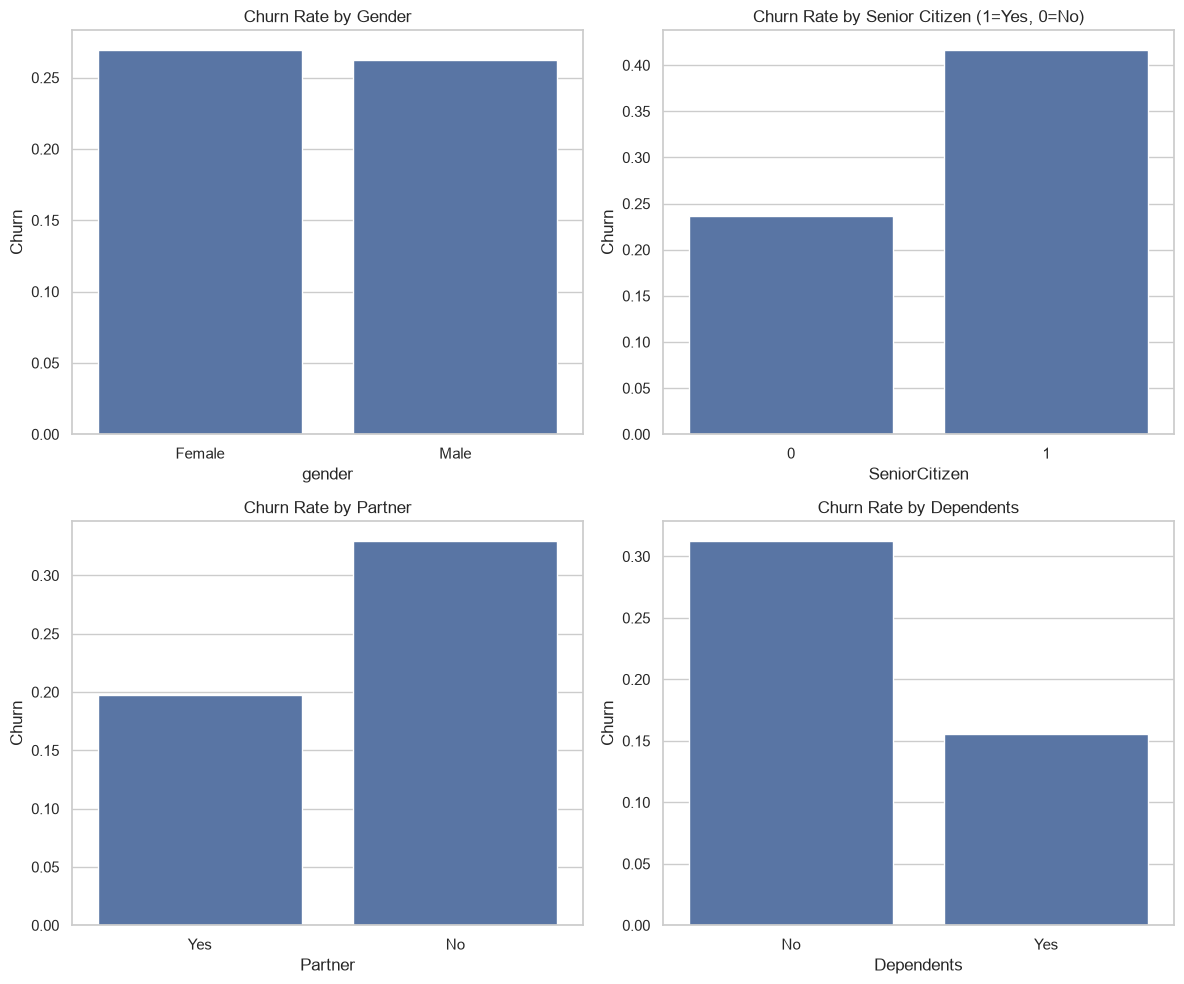

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

#plotting Churn rates for demographics
sns.barplot(x='gender', y='Churn', data=df, ax=axes[0,0], errorbar=None)
axes[0,0].set_title('Churn Rate by Gender')

sns.barplot(x='SeniorCitizen', y='Churn', data=df, ax=axes[0,1], errorbar=None)
axes[0,1].set_title('Churn Rate by Senior Citizen (1=Yes, 0=No)')

sns.barplot(x='Partner', y='Churn', data=df, ax=axes[1,0], errorbar=None)
axes[1,0].set_title('Churn Rate by Partner')

sns.barplot(x='Dependents', y='Churn', data=df, ax=axes[1,1], errorbar=None)
axes[1,1].set_title('Churn Rate by Dependents')

plt.tight_layout()
plt.show()

### Demographic Insights

* **Gender:** Male and female customers exhibit nearly identical churn rates (~26%). Gender is not a significant predictor of whether a customer will leave.

* **Senior Citizen:** Senior citizens have a notably higher churn rate (~41%) compared to non-seniors (~23%), indicating they may need targeted retention strategies.

* **Partner & Dependents:** Customers without partners or dependents are significantly more likely to churn. Customers in family households demonstrate much higher stability.

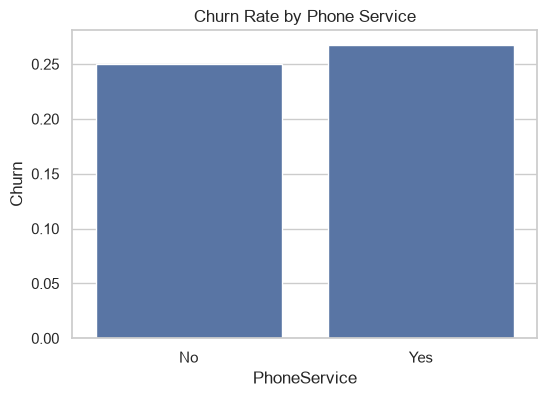

In [9]:
plt.figure(figsize=(6, 4))
sns.barplot(x='PhoneService', y='Churn', data=df, errorbar=None)
plt.title('Churn Rate by Phone Service')
plt.show()

### Service Insights

* **Phone Service:** The presence or absence of phone service has almost no impact on churn. Both groups leave at similar rates (25% vs 26%), meaning phone service alone does not heavily influence customer loyalty.

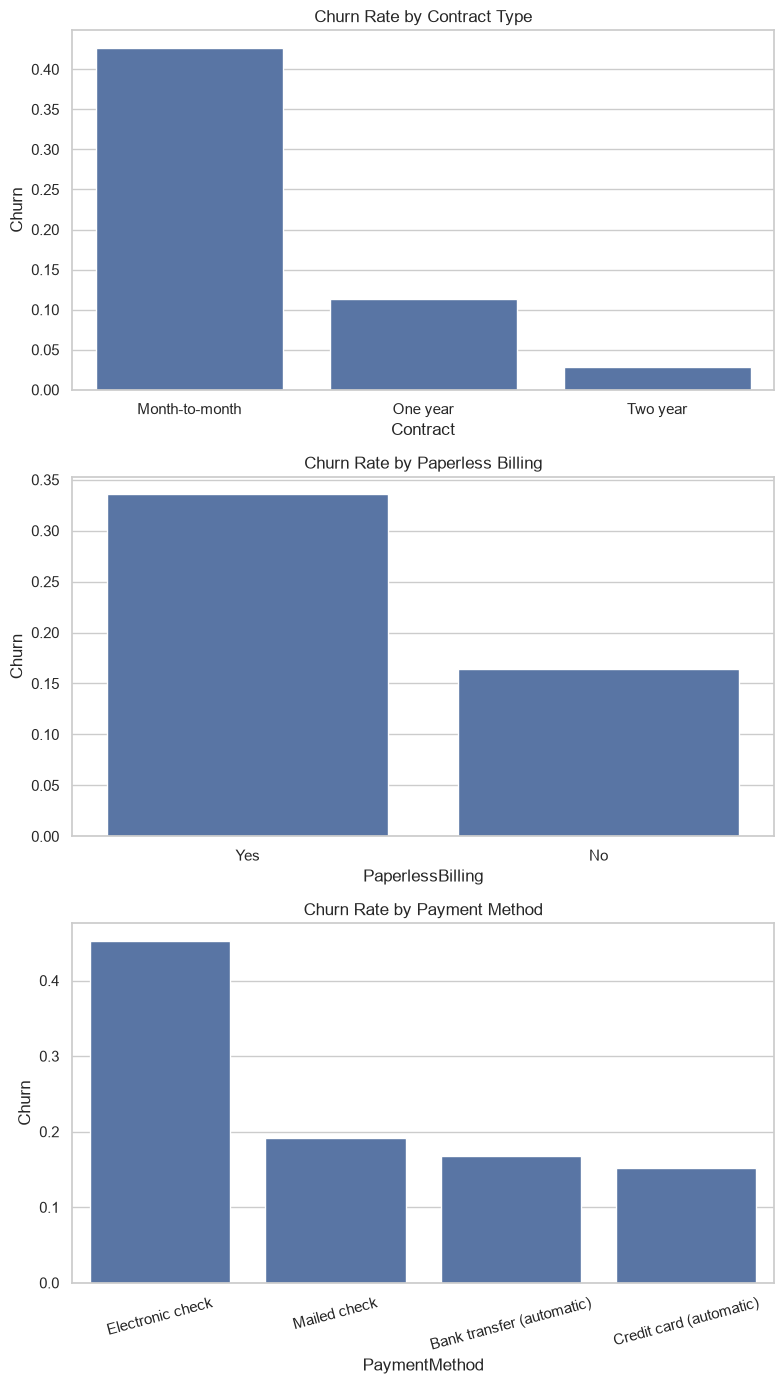

In [10]:
fig, axes = plt.subplots(3, 1, figsize=(8, 14))

sns.barplot(x='Contract', y='Churn', data=df, ax=axes[0], errorbar=None)
axes[0].set_title('Churn Rate by Contract Type')

sns.barplot(x='PaperlessBilling', y='Churn', data=df, ax=axes[1], errorbar=None)
axes[1].set_title('Churn Rate by Paperless Billing')

sns.barplot(x='PaymentMethod', y='Churn', data=df, ax=axes[2], errorbar=None)
axes[2].set_title('Churn Rate by Payment Method')
plt.xticks(rotation=15) # Rotate labels so they don't overlap

plt.tight_layout()
plt.show()

### Payments Insights

* **Contract:** Contract length is a massive driver of churn. Customers on month-to-month contracts leave at a high rate (~42%), whereas those locked into one-year (~11%) or two-year (~2%) contracts rarely leave.

* **Paperless Billing:** Interestingly, customers who use paperless billing churn at a higher rate (~33%) compared to those receiving traditional paper bills (~16%).

* **Payment Method:** Customers paying via "Electronic check" are the most likely to churn (~45%). Automated payment methods, like bank transfers and credit cards, are strongly associated with much better retention (~15-16%).